In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scipy
import skimage
from osgeo import gdal

import PolSARInversion
import pickle

#### A Machine Learning Approach on SMOS Thin Sea Ice Thickness Retrieval (Macia et al. 2024)
SRC : (https://ieeexplore.ieee.org/stamp/stamp.jsp?arnumber=10543019)

In [3]:
import importlib
importlib.reload(PolSARInversion)

<module 'PolSARInversion' from '/mnt/c/Users/admin/Desktop/rnd/AISat/VolumeInversion/PolSARInversion.py'>

In [17]:
loadNew = False

noCache = loadNew
if(not loadNew):
    try:
        s1s2grouped = pickle.load(open("ALOSPolarimetric_slc_cached.pickle", 'rb'))
        s1 = s1s2grouped[0]
        s2 = s1s2grouped[1]
    except:
        noCache = True

if(loadNew or noCache):
    
    #fn1 = "/mnt/d/slc_arcticarchi/cr0819-ALPSRP175641510-L1.1/VOL-ALPSRP175641510-P1.1__A"
    #fn2 = "/mnt/d/slc_arcticarchi/cr0819-ALPSRP173161510-L1.1/VOL-ALPSRP173161510-P1.1__A"
    fn1 = "/mnt/d/slc_arcticarchi/cr0825-ALPSRP174611590-L1.1/VOL-ALPSRP174611590-P1.1__A"
    fn2 = "/mnt/d/slc_arcticarchi/cr0825-ALPSRP176361590-L1.1/VOL-ALPSRP176361590-P1.1__A"
    
    s1_src = gdal.Open(fn1, gdal.GA_ReadOnly)
    s2_src = gdal.Open(fn2, gdal.GA_ReadOnly)

    sample_rate = 10
    crop_frac = 0
    
    s1 = s1_src.ReadAsArray()
    if (crop_frac < 1 and crop_frac != 0):
        midpoint = np.array(s1.shape) // 2
        s1 = s1[:, midpoint[1] - int(s1.shape[1]*crop_frac/2):midpoint[1] + int(s1.shape[1]*crop_frac/2),
                   midpoint[2] - int(s1.shape[2]*crop_frac/2):midpoint[2] + int(s1.shape[2]*crop_frac/2)]
    if (sample_rate > 1):
        djj = np.array([i for i in range(s1.shape[1]) if i % 10 == 0])
        dkk = np.array([i for i in range(s1.shape[2]) if i % 10 == 0])
        s1 = s1[:, djj[:, np.newaxis], dkk[:, np.newaxis, np.newaxis]][:,:,:,0]
    
    s2 = s2_src.ReadAsArray()
    if (crop_frac < 1 and crop_frac != 0):
        midpoint = np.array(s2.shape) // 2
        s2 = s2[:, midpoint[1] - int(s2.shape[1]*crop_frac/2):midpoint[1] + int(s2.shape[1]*crop_frac/2),
                   midpoint[2] - int(s2.shape[2]*crop_frac/2):midpoint[2] + int(s2.shape[2]*crop_frac/2)]
    if (sample_rate > 1):
        djj = np.array([i for i in range(s2.shape[1]) if i % 10 == 0])
        dkk = np.array([i for i in range(s2.shape[2]) if i % 10 == 0])
        s2 = s2[:, djj[:, np.newaxis], dkk[:, np.newaxis, np.newaxis]][:,:,:,0]

    s1s2grouped = (s1, s2)
    pickle.dump(s1s2grouped, open("ALOSPolarimetric_slc_cached.pickle", 'wb'))

In [18]:
s1_src = None
s2_src = None
#np.min((s1.shape, s2.shape), axis=0)
s1.shape

(4, 109, 1844)

In [46]:
ninds = np.min((s1.shape, s2.shape), axis=0)
s1o, s2o = s1[:, :ninds[1], :ninds[2]].copy(), s2[:, :ninds[1], :ninds[2]].copy()

tmp1, tmp2 = s1o, s2o

y, x = -22, -350 #eyeballed displacement
tmp2 = np.zeros(s1o.shape).astype(complex)
tmp1 = np.zeros(s1o.shape).astype(complex)
for i in range(s2o.shape[1]):
    if (i + y < 0 or i + y >= s1o.shape[1]): continue
    for j in range(s2o.shape[2]):
        if (j + x < 0 or j + x >= s1o.shape[2]): continue
        tmp2[:,i+y,j+x] = s2o[:,i,j]
        tmp1[:,i+y,j+x] = s1o[:,i+y,j+x]
tmp1, tmp2 = np.trim_zeros(tmp1), np.trim_zeros(tmp2)

#plt.imshow(np.log1p(np.abs(tmp1[0])), aspect=5); plt.show()
#plt.imshow(np.log1p(np.abs(tmp2[0])), aspect=5);

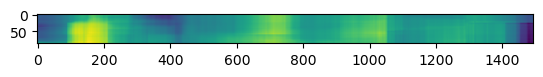

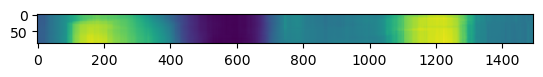

In [50]:
flow = skimage.registration.optical_flow_ilk(np.abs(tmp2[0]), np.abs(tmp1[0]), radius=60, num_warp=10)
tmp = np.meshgrid(np.arange(tmp2.shape[1]), np.arange(tmp2.shape[2]), indexing='ij');
tmp = np.array([tmp[0]-flow[0], tmp[1]-flow[1]])
tmp2 = np.array([scipy.ndimage.map_coordinates(tmp2[i].real, tmp).astype(complex) +
                scipy.ndimage.map_coordinates(tmp2[i].imag, tmp) * 1j for i in range(tmp2.shape[0])])
plt.imshow(flow[0]); plt.show()
plt.imshow(flow[1])
s1o, s2o = tmp1, tmp2

In [57]:
#plt.imshow(np.log1p(np.abs(s1o[0])), aspect=5); plt.show()
#plt.imshow(np.log1p(np.abs(s2o[0])), aspect=5);

Text(0.5, 1.0, 'salinity profile of 3m thick ice')

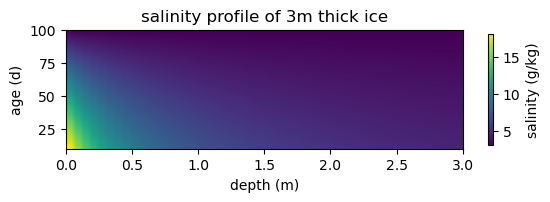

In [156]:
#plt.imshow(np.abs(s1o[0]), aspect=8); plt.show()
#plt.imshow(np.abs(s2o[0]), aspect=8);

#def extinction(z, h, t): #z (depth) increases downwards
#    return 35*(z/h)/(0.1*t)
def extinction(z, h, t):
    return 15*(z/h)/(0.1*t) + 3.1

# CHECK THIS: https://link.springer.com/article/10.1007/s13131-016-0922-x
#   Arctic sea ice thickness changes in terms of sea ice age  (Bi et al., 2016)
#   Seawater dielectric constant (https://ntrs.nasa.gov/api/citations/20110008152/downloads/20110008152.pdf) - see page 35

tmp_h = 3
tmp_z = np.linspace(0, 3, 50)
tmp_t = np.linspace(10, 100, 50)
tmp_z, tmp_t = np.meshgrid(tmp_z, tmp_t, indexing='ij')
plt.imshow(extinction(tmp_z, tmp_h, tmp_t), extent=[0, 3, 10, 100], aspect=0.01)
plt.ylabel("age (d)"); plt.xlabel("depth (m)");
plt.colorbar(shrink = 0.3, label="salinity (g/kg)")
plt.title("salinity profile of 3m thick ice")

In [157]:
importlib.reload(PolSARInversion)
cohs = PolSARInversion.stackcoh(s1o, s2o, window_size=3)
rvow = PolSARInversion.RVoW(cohs, extinction, np.radians(45.0), np.radians(5), wavelength=0.236)

#plt.imshow(rvow.icesurf_phase, aspect=10)
#plt.colorbar(shrink = 0.3)

#tmp = rvow.data_modelled(rvow.params)
#plt.imshow(np.abs(tmp[1]), aspect=5)
#plt.colorbar(shrink=0.2)

Beginning coherence function mapping...
(8000, 3) (8000,) (20, 20, 20)
coherence function initialized.


[          ]0.0% - 0/100
[#         ]10.0% - 10/100
[##        ]20.0% - 20/100
[###       ]30.0% - 30/100
[####      ]40.0% - 40/100
[#####     ]50.0% - 50/100
[######    ]60.0% - 60/100
[#######   ]70.0% - 70/100
[########  ]80.0% - 80/100
[######### ]90.0% - 90/100


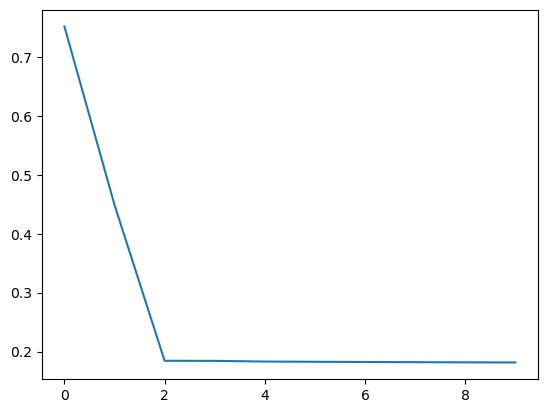

In [161]:
rvow.lr = 0.05
error_hist = rvow.converge(100, np.array([0.1, 0.0001, 0.1, 0.01, 0.01, 0.01, 0.01]))
plt.plot(error_hist)

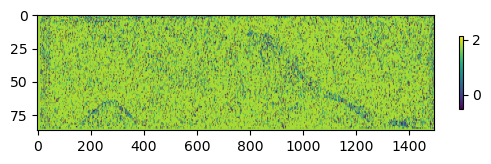

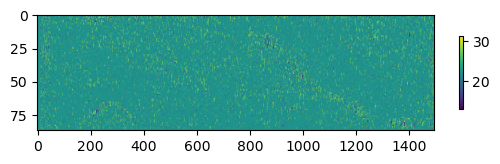

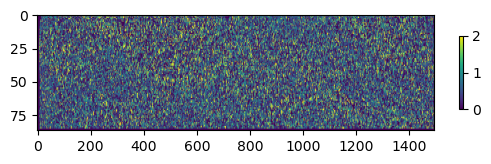

In [162]:
plt.imshow(rvow.params[0], aspect=5); plt.colorbar(shrink=0.2); plt.show()
plt.imshow(rvow.params[1], aspect=5); plt.colorbar(shrink=0.2); plt.show()
#plt.imshow(np.sum(rvow.params[3:], axis=0), aspect=5); plt.colorbar(shrink=0.3); plt.show()
plt.imshow((rvow.params[3]+rvow.params[6])/(1+rvow.params[4]+rvow.params[5]), aspect=5); plt.colorbar(shrink=0.2); plt.show()

#plt.imshow(rvow.params[3], aspect=8); plt.colorbar(shrink=0.2); plt.show()
#plt.imshow(rvow.params[4], aspect=8); plt.colorbar(shrink=0.2); plt.show()
#plt.imshow(rvow.params[5], aspect=8); plt.colorbar(shrink=0.2); plt.show()
#plt.imshow(rvow.params[6], aspect=8); plt.colorbar(shrink=0.2); plt.show()

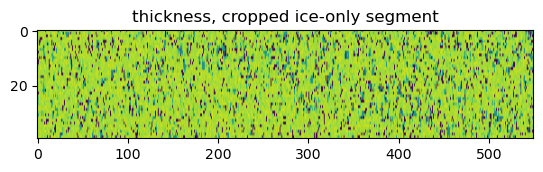

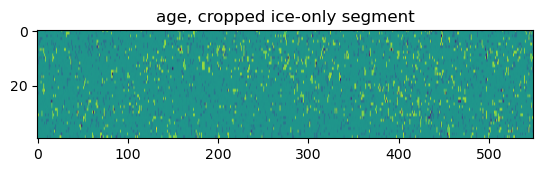

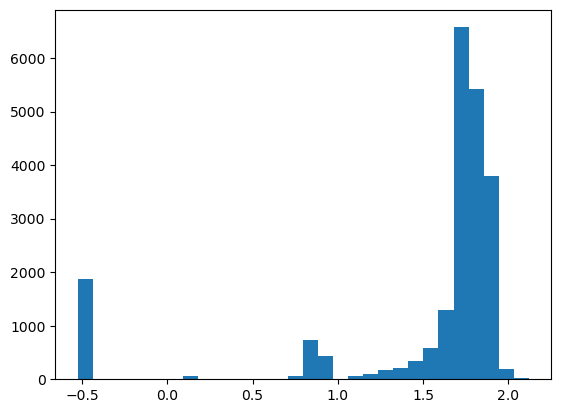

In [198]:
plt.imshow((rvow.params[0,10:50,50:600]), aspect=3); plt.title("thickness, cropped ice-only segment"); plt.show()
plt.imshow((rvow.params[1,10:50,50:600]), aspect=3); plt.title("age, cropped ice-only segment"); plt.show()
plt.hist(rvow.params[0, 10:50, 50:600].ravel(), bins=30); plt.show()
#plt.hist(rvow.params[1, 10:50, 50:600].ravel(), bins=30); plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..42.21833339337348].


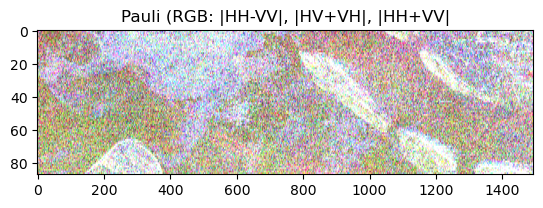

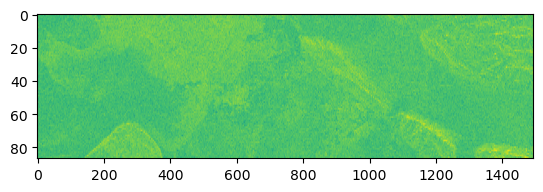

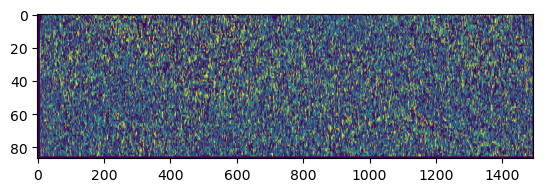

In [194]:
#plt.figure(figsize = (15,5))
rgb_hh_hv_vh = np.stack([(np.abs(s1o[0] - s1o[3])),
                         (np.abs(s1o[1] + s1o[2])),
                         (np.abs(s1o[1] + s1o[3]))], axis=-1)
a = np.mean(np.mean(rgb_hh_hv_vh, axis=0), axis=0)
rgb_hh_hv_vh /= a[np.newaxis, np.newaxis, :]
plt.imshow(rgb_hh_hv_vh, aspect=5);
plt.title("Pauli (RGB: |HH-VV|, |HV+VH|, |HH+VV|")
plt.show()

plt.imshow(np.log1p(np.abs(s1o[0])), aspect=5); plt.show()
plt.imshow((rvow.params[3]+rvow.params[6])/(1+rvow.params[4]+rvow.params[5]), aspect=5); plt.show()
#plt.imshow((rvow.params[4]), aspect=4); plt.show()
#plt.imshow((rvow.params[5]), aspect=4); plt.show()
#plt.imshow((rvow.params[6]), aspect=4); plt.show()

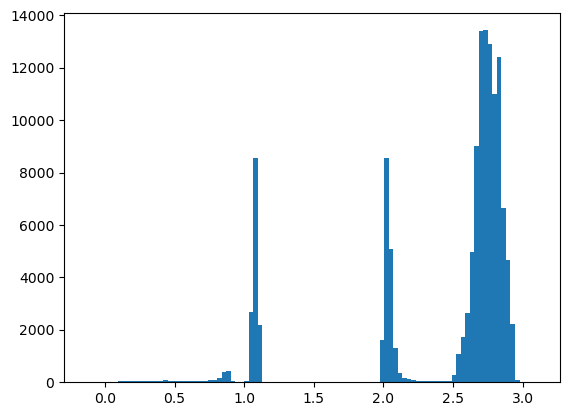

In [99]:
th_tweak = rvow.params[0, :50, :500].ravel().copy()
#th_tweak[th_tweak < 0] = th_tweak[th_tweak < 0] * -1
plt.hist(rvow.params[0].ravel(), bins=100); plt.show()

In [254]:
np.max(np.abs(s2o[0]))

np.float64(610833.6620025552)

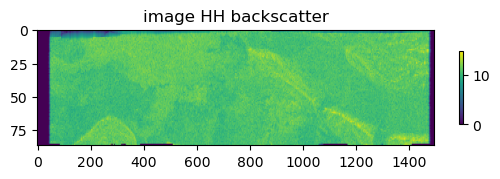

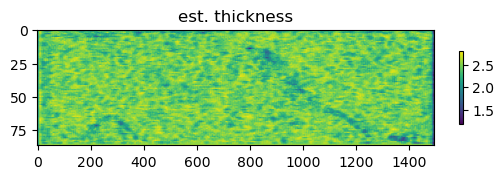

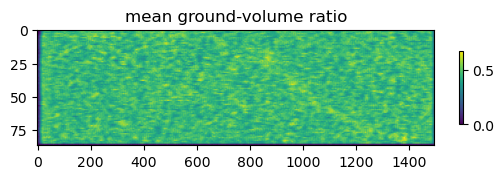

In [144]:
tmp_aspect = 5

plt.imshow(np.log1p(np.abs(s2o[0])), aspect=tmp_aspect); plt.colorbar(shrink=0.2); plt.title("image HH backscatter"); plt.show()

a, b = np.abs(np.linspace(-5, 5, 5)), np.abs(np.linspace(-5, 5, 20))
a, b = np.meshgrid(a, b, indexing='ij')
window = np.exp(-(a*b)); window /= np.sum(window)

pm_thickness = scipy.signal.convolve2d(rvow.params[0], window, mode='same')
plt.imshow(pm_thickness, aspect=tmp_aspect); plt.colorbar(shrink=0.2); plt.title("est. thickness"); plt.show()

pm_gvr = scipy.signal.convolve2d(np.mean(rvow.params[3:], axis=0), window, mode='same')
plt.imshow(pm_gvr, aspect=tmp_aspect); plt.colorbar(shrink=0.2); plt.title("mean ground-volume ratio"); plt.show()

### SECTION 2 - VVHHr Dielectric Inversion
It beginsssss.

In [140]:
vvhhr = np.abs(s1o[3])/np.abs(s1o[0])
vvhhr[np.isnan(vvhhr)] = 0

solver = PolSARInversion.IceVVHHr(vvhhr[np.newaxis, :], 21.5)

/tmp/ipykernel_404/2020420557.py:1: RuntimeWarning: invalid value encountered in divide
  vvhhr = np.abs(s1o[3])/np.abs(s1o[0])


[          ]0.0% - 0/500
[          ]2.0% - 10/500
[          ]4.0% - 20/500
[          ]6.0% - 30/500
[          ]8.0% - 40/500
[#         ]10.0% - 50/500
[#         ]12.0% - 60/500
[#         ]14.0% - 70/500
[#         ]16.0% - 80/500
[#         ]18.0% - 90/500
[##        ]20.0% - 100/500
[##        ]22.0% - 110/500
[##        ]24.0% - 120/500
[##        ]26.0% - 130/500
[##        ]28.0% - 140/500
[###       ]30.0% - 150/500
[###       ]32.0% - 160/500
[###       ]34.0% - 170/500
[###       ]36.0% - 180/500
[###       ]38.0% - 190/500
[####      ]40.0% - 200/500
[####      ]42.0% - 210/500
[####      ]44.0% - 220/500
[####      ]46.0% - 230/500
[####      ]48.0% - 240/500
[#####     ]50.0% - 250/500
[#####     ]52.0% - 260/500
[#####     ]54.0% - 270/500
[#####     ]56.0% - 280/500
[#####     ]58.0% - 290/500
[######    ]60.0% - 300/500
[######    ]62.0% - 310/500
[######    ]64.0% - 320/500
[######    ]66.0% - 330/500
[######    ]68.0% - 340/500
[#######   ]70.0% - 350/500
[#######

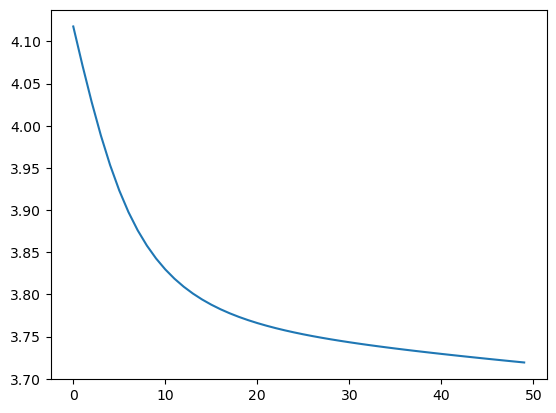

In [141]:
solver.lr = 0.01
error_hist = solver.converge(500, np.array([0.001, 0.01]))
plt.plot(error_hist)

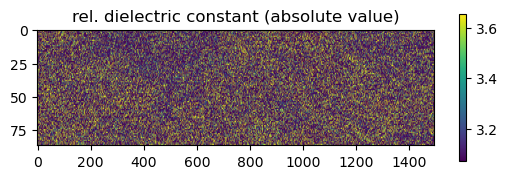

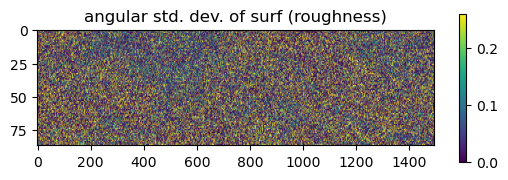

In [143]:
#a, b = np.abs(np.linspace(-5, 5, 2)), np.abs(np.linspace(-5, 5, 8))
#a, b = np.meshgrid(a, b, indexing='ij')
#window = np.exp(-(a*b)); window /= np.sum(window)
#pm_dielectric = scipy.signal.convolve2d(solver.params[0], window, mode='same')
#plt.imshow(pm_dielectric, aspect=10)

plt.imshow(solver.params[0], aspect=5)
plt.colorbar(shrink=0.4)
plt.title('rel. dielectric constant (absolute value)')
plt.show()

plt.imshow(solver.params[1], aspect=5)
plt.colorbar(shrink = 0.4)
plt.title('angular std. dev. of surf (roughness)')
plt.show()

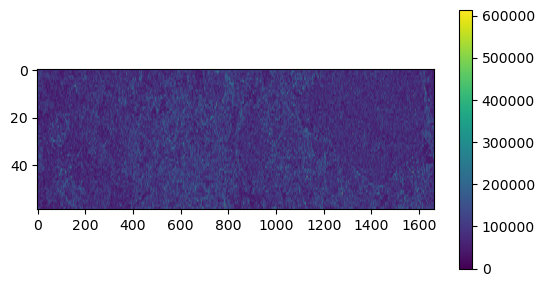

In [13]:
plt.imshow(np.abs(s1o[0]), aspect=10)
plt.colorbar(shrink=0.7)

In [ ]:
# https://www.google.com/search?client=firefox-b-d&q=ice+dielectric+constant+and+brine+fraction
# CHECK THIS DOCUMENT